# Contracts

Each instrument, priced on the sample market and checked against its formula. The market is
`examples.sample_market()`: spot 17.50 on 16 September 2026, domestic rate 7%, foreign rate
4%, volatility 12%.

A forward's value is `(forward - strike) * discount factor * volume`, signed by buy or sell.
A European option is Black-76 on the forward, the volatility and the discount factor. An Asian
averages the fixing dates that have already passed and the forwards that have not.


In [9]:
import logging
import math
from datetime import date

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import matplotlib.pyplot as plt
import sjd
from sjd import examples

sjd.set_log_level("INFO")

market = examples.sample_market()
environment = market["environment"]
sjd.require_valid(environment)
forward_curve = market["forward"]
discount = market["discount"]
volatility = market["volatility"]
settlement = market["collar_settlement"]
maturity = market["collar_maturity"]
strike = round(forward_curve.get_forward(settlement) * 0.98, 2)
volume = 1_000.0
print(market["anchor"], "settlement", settlement, "strike", strike)


2026-09-16 settlement 2026-12-17 strike 17.28


## Forwards

`EuropeanForward(settlement, strike, volume, buy_sell)` is physically settled: the rate-set
date is the settlement date. Passing a maturity as well makes a cash-settled forward, with
the rate set on the maturity and the cash paid on the settlement. Both read the forward on
the settlement date, so the same strike gives the same value.


In [10]:
physical = sjd.EuropeanForward(settlement, strike, volume, sjd.BuySell.BUY)
cash = sjd.EuropeanForward(maturity, settlement, strike, volume, sjd.BuySell.BUY)
sjd.require_valid(physical, environment)
sjd.require_valid(cash, environment)

level = forward_curve.get_forward(settlement)
factor = discount.get_discount_factor(settlement)
expected = (level - strike) * factor * volume

assert physical.maturity_date() == physical.settlement_date() == settlement
assert cash.maturity_date() == maturity
assert cash.settlement_date() == settlement
assert cash.maturity_date() != cash.settlement_date()
assert physical.volume == volume
assert physical.buy_sell == sjd.BuySell.BUY
assert math.isclose(physical.get_value(environment), expected)
assert math.isclose(cash.get_value(environment), physical.get_value(environment))
assert math.isclose(physical.get_payoff(20.0), (20.0 - strike) * volume)
assert "EuropeanForward" in repr(physical)
print(repr(physical))
print(f"value {physical.get_value(environment):.4f}")


sjd.EuropeanForward(settlement=2026-12-17, strike=17.28, volume=1000.0)
value 346.6597


## European options

`get_option_value` is the Black-76 premium times the volume. It does not apply the premium
cashflow or the buy/sell sign. `get_value` does both: a bought option is the premium minus
the discounted premium amount, and a sold option changes sign.

The standard deviation passed to Black-76 is the flat volatility times the square root of
the Actual/365 year fraction from the anchor to the maturity.


In [11]:
def black76(option_type, contract_strike, premium_amount, buy_sell):
    contract = sjd.EuropeanOption(
        maturity=maturity,
        settlement=settlement,
        strike=contract_strike,
        type=option_type,
        volume=volume,
        premium_payment_date=settlement,
        premium_amount=premium_amount,
        buy_sell=buy_sell,
    )
    sjd.require_valid(contract, environment)
    year_fraction = examples.year_fraction(maturity)
    standard_deviation = volatility.get_volatility(maturity) * math.sqrt(year_fraction)
    formula_type = sjd.Black76Call if option_type == sjd.PutCall.CALL else sjd.Black76Put
    formula = formula_type(level, contract_strike, standard_deviation, factor)
    return contract, formula.premium() * volume

bought, call_premium = black76(sjd.PutCall.CALL, strike, 0.25, sjd.BuySell.BUY)
sold, put_premium = black76(sjd.PutCall.PUT, strike, 0.0, sjd.BuySell.SELL)

assert math.isclose(bought.get_option_value(environment), call_premium)
assert math.isclose(
    bought.get_value(environment),
    call_premium - 0.25 * volume * factor,
)
assert math.isclose(sold.get_option_value(environment), put_premium)
assert math.isclose(sold.get_value(environment), -put_premium)
assert "EuropeanOption" in repr(bought)
print(repr(bought))
print(f"call {bought.get_option_value(environment):.4f}")
print(f"put  {sold.get_option_value(environment):.4f}")


sjd.EuropeanOption(maturity=2026-12-14, strike=17.28, volume=1000.0)
call 602.0667
put  255.4070


## Asians

`AverageRateCall` and `AverageRatePut` are the formulas. With one forward still to be set
and no fixings, each premium is Black-76. An `AsianOption` on a single averaging date is
that case: its option value is the formula premium times the volume.

A calendar-month forward uses one pillar for every day in the pillar's month.
`VolatilityCurveCMA` does the same for volatility. A date before the anchor is read from
the fixing curve, and the later dates are read from the forward. The first pillar here is
after the anchor, so the curve records a flat-backfill warning and remains valid.


In [12]:
one_forward = 100.0
one_deviation = 0.2
one_factor = 0.97
assert math.isclose(
    sjd.AverageRateCall([one_forward], [], one_forward, [one_deviation], one_factor).premium(),
    sjd.Black76Call(one_forward, one_forward, one_deviation, one_factor).premium(),
)
assert math.isclose(
    sjd.AverageRatePut([one_forward], [], one_forward, [one_deviation], one_factor).premium(),
    sjd.Black76Put(one_forward, one_forward, one_deviation, one_factor).premium(),
)

single_day = market["forward_settlement"]
single = sjd.AsianOption(
    averaging_dates=[single_day],
    settlement=market["asian_settlement"],
    strike=strike,
    type=sjd.PutCall.CALL,
    volume=volume,
    premium_payment_date=market["asian_settlement"],
    premium_amount=0.0,
    buy_sell=sjd.BuySell.BUY,
)
sjd.require_valid(single, environment)
single_deviation = volatility.get_volatility(single_day) * math.sqrt(
    examples.year_fraction(single_day)
)
single_premium = (
    sjd.Black76Call(
        forward_curve.get_forward(single_day),
        strike,
        single_deviation,
        discount.get_discount_factor(market["asian_settlement"]),
    ).premium()
    * volume
)
assert math.isclose(single.get_option_value(environment), single_premium)
assert single.averaging_dates() == [single_day]
print(repr(single))
print(f"single-date asian {single.get_option_value(environment):.4f}")


sjd.AsianOption(settlement=2027-07-02, averages=1, strike=17.28)
single-date asian 816.1648


In [13]:
anchor = market["anchor"]
month_pillars = [date(2026, 10, 1), date(2026, 12, 1)]
monthly_forward = sjd.ForwardCurve(
    anchor,
    month_pillars,
    [17.40, 17.80],
    averaging=sjd.ForwardAveraging.CALENDAR_MONTH,
)
monthly_volatility = sjd.VolatilityCurveCMA(anchor, month_pillars, [0.12, 0.20])
curve_end = date(2026, 12, 16)
monthly_discount = sjd.DiscountCurve(
    anchor,
    [anchor, curve_end],
    [1.0, math.exp(-examples.DOMESTIC_RATE * examples.year_fraction(curve_end))],
)
monthly_fixings = sjd.DailyFixingCurve([date(2026, 9, 15)], [examples.SPOT])
monthly = sjd.RatesEnvironment(anchor)
monthly.set_frs(monthly_forward)
monthly.set_drs(monthly_discount)
monthly.set_vrs(monthly_volatility)
monthly.set_fixing_rs(monthly_fixings)

curve_report = monthly_forward.validate()
assert curve_report.ok
assert any(issue.code == "RATE_SOURCE_FLAT_BACKFILL" for issue in curve_report.issues)
assert math.isclose(monthly_forward.get_forward(date(2026, 10, 15)), 17.40)
assert math.isclose(monthly_forward.get_forward(date(2026, 10, 28)), 17.40)
assert math.isclose(monthly_fixings.get_rate(date(2026, 9, 15)), examples.SPOT)
curve_report


WARNING sjd._core: Anchor has no observation; values are flat through the first observation


severity,path,code,message
WARNING,forward_curve_cma/anchor_date,RATE_SOURCE_FLAT_BACKFILL,Anchor has no observation; values are flat through the first observation


In [14]:
averages = [date(2026, 9, 15), date(2026, 10, 15), date(2026, 10, 28)]
asian_settlement = date(2026, 11, 2)
asian_strike = 17.0
asian = sjd.AsianForward(averages, asian_settlement, asian_strike, 10.0, sjd.BuySell.BUY)
asian_option = sjd.AsianOption(
    averages,
    asian_settlement,
    asian_strike,
    sjd.PutCall.PUT,
    10.0,
    asian_settlement,
    0.0,
    sjd.BuySell.BUY,
)
sjd.require_valid(asian, monthly)
sjd.require_valid(asian_option, monthly)

average_level = (examples.SPOT + 17.40 + 17.40) / 3.0
asian_factor = monthly_discount.get_discount_factor(asian_settlement)
assert math.isclose(
    asian.get_value(monthly), (average_level - asian_strike) * asian_factor * 10.0
)
assert math.isfinite(asian_option.get_option_value(monthly))
assert "AsianForward" in repr(asian)
print(repr(asian))
print(f"asian forward {asian.get_value(monthly):.4f}")
print(f"asian option  {asian_option.get_value(monthly):.4f}")


WARNING sjd._core: Anchor has no observation; values are flat through the first observation
WARNING sjd._core: Anchor has no observation; values are flat through the first observation
WARNING sjd._core: Anchor has no observation; values are flat through the first observation
WARNING sjd._core: Anchor has no observation; values are flat through the first observation


sjd.AsianForward(settlement=2026-11-02, averages=3, strike=17.0)
asian forward 4.2946
asian option  0.2944


## Cashflows

`FixedCashflow` pays its volume, signed by buy or sell, discounted on the settlement date.
The payoff does not depend on the spot. `Cashflow` is the same class.


In [15]:
assert sjd.Cashflow is sjd.FixedCashflow
bought_cash = sjd.FixedCashflow(settlement, 1000.0, sjd.BuySell.BUY)
sold_cash = sjd.Cashflow(settlement, 1000.0, sjd.BuySell.SELL)
sjd.require_valid(bought_cash, environment)
sjd.require_valid(sold_cash, environment)

assert bought_cash.maturity_date() == settlement
assert math.isclose(bought_cash.get_value(environment), 1000.0 * factor)
assert math.isclose(sold_cash.get_value(environment), -1000.0 * factor)
assert math.isclose(bought_cash.get_payoff(0.0), 1000.0)
assert math.isclose(sold_cash.get_payoff(50.0), -1000.0)
print(repr(bought_cash))
print(f"cashflow {bought_cash.get_value(environment):.4f}")


sjd.FixedCashflow(settlement=2026-12-17, volume=1000.0)
cashflow 982.5109


## Stresses

`ContractStressor` revalues the forward on the base environment and on each stressed curve.
The value is `(forward - strike) * discount factor * volume`. The chart is the change from
the base for the discount-factor and volatility stresses. Adding one unit to the forward
changes this contract by about 982, so that stress is printed on its own. Volatility does
not enter the value, so its change is zero.


Fwd + 1unit +982.51
   -0.8220  Domestic DF + 1% NACA a/360
   +0.0006  Domestic ZC Stress base
   +0.0355  Domestic DF 1 bp ZC Stress at 3m
   +0.0010  Domestic DF 1 bp ZC Stress at 6m
   +0.0006  Domestic DF 1 bp ZC Stress at 9m
   +0.0006  Domestic DF 1 bp ZC Stress at 12m
   +0.0006  Domestic DF 1 bp ZC Stress at 15m
   +0.0006  Domestic DF 1 bp ZC Stress at 18m
   +0.0006  Domestic DF 1 bp ZC Stress at 21m
   +0.0000  Vol + 1% 


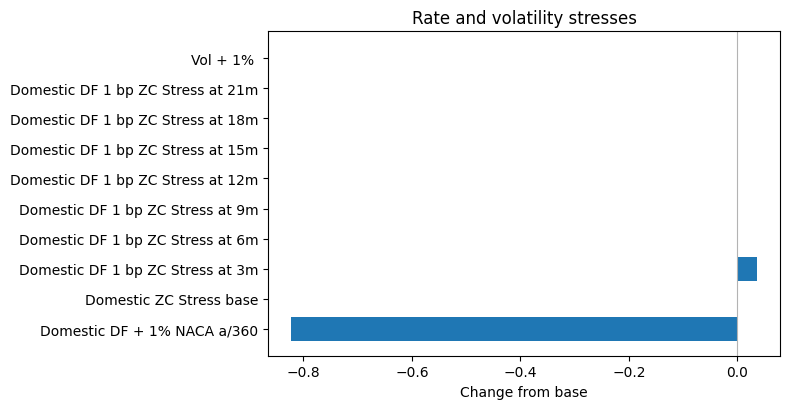

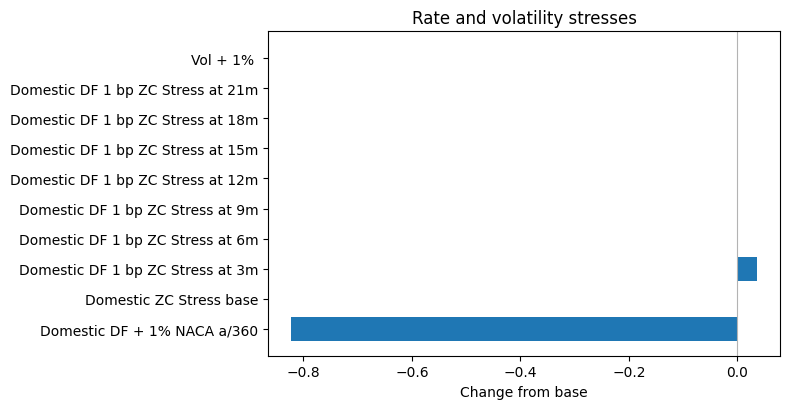

In [16]:
stressed = sjd.ContractStressor(physical, environment).stressed_values()
base = stressed["Base"]
changes = {name: value - base for name, value in stressed.items() if name != "Base"}
assert math.isclose(base, physical.get_value(environment))
assert not math.isclose(changes["Fwd + 1unit"], 0.0)
assert math.isclose(changes["Vol + 1% "], 0.0, abs_tol=1e-12)
assert not math.isclose(changes["Domestic DF + 1% NACA a/360"], 0.0)
assert not math.isclose(changes["Domestic DF 1 bp ZC Stress at 3m"], 0.0, abs_tol=1e-6)

print(f"Fwd + 1unit {changes.pop('Fwd + 1unit'):+.2f}")
for name, change in changes.items():
    print(f"{change:+10.4f}  {name}")

figure, axis = plt.subplots(figsize=(8, 0.32 * len(changes) + 1))
axis.barh(list(changes), list(changes.values()))
axis.axvline(0.0, color="0.7", linewidth=0.8)
axis.set_xlabel("Change from base")
axis.set_title("Rate and volatility stresses")
figure.tight_layout()
figure


## What can go wrong

A negative strike is the contract's own input, so it is the first issue. An empty
environment then adds the missing curves. `is_valid` only reads the last report: it stays
true until `validate` runs, and it stays false afterwards until `validate` runs again.
An option checked against a market with no volatility reports the missing source.
`Black76Call` is a formula, not a validatable object, so a bad input is a
`ConfigurationError` at construction.


In [17]:
empty = sjd.RatesEnvironment(market["anchor"])
bad_forward = sjd.EuropeanForward(settlement, -1.0, volume, sjd.BuySell.BUY)
assert bad_forward.report.issues == ()
assert bad_forward.is_valid

strike_report = bad_forward.validate(empty)
assert not strike_report.ok
assert not bad_forward.is_valid
assert [issue.code for issue in strike_report.issues] == [
    "CONTRACT_STRIKE_NEGATIVE",
    "RATES_ENVIRONMENT_NO_RATES",
    "MARKET_DISCOUNT_RATE_SOURCE_MISSING",
    "MARKET_FORWARD_RATE_SOURCE_MISSING",
]
assert strike_report.issues[0].path == ("european_forward", "strike")
strike_report


severity,path,code,message
ERROR,european_forward/strike,CONTRACT_STRIKE_NEGATIVE,Strike is negative
ERROR,european_forward/rates_environment,RATES_ENVIRONMENT_NO_RATES,No rates set
ERROR,european_forward/rates_environment/discount_rate_source,MARKET_DISCOUNT_RATE_SOURCE_MISSING,No discounting rate source
ERROR,european_forward/rates_environment/forward_rate_source,MARKET_FORWARD_RATE_SOURCE_MISSING,No forward rate source


In [18]:
assert bought.is_valid
lagging = bought.validate(empty)
assert not lagging.ok
assert not bought.is_valid
restored = bought.validate(environment)
assert restored.ok
assert bought.is_valid

no_volatility = sjd.RatesEnvironment(market["anchor"])
no_volatility.set_frs(forward_curve)
no_volatility.set_drs(discount)
missing_vol = bought.validate(no_volatility)
assert [issue.code for issue in missing_vol.issues] == ["MARKET_VOLATILITY_RATE_SOURCE_MISSING"]
bought.validate(environment)
missing_vol


severity,path,code,message
ERROR,european_option/rates_environment/volatility_rate_source,MARKET_VOLATILITY_RATE_SOURCE_MISSING,No volatiltiy rate source


In [19]:
try:
    formula = sjd.Black76Call(0.0, strike, 0.2, 1.0)
except sjd.ConfigurationError as error:
    assert isinstance(error, ValueError)
    assert error.code == "CONFIGURATION"
    formula = None
    print(error)
else:
    raise AssertionError("a zero forward is not a Black-76 input")
assert formula is None


Black76 forward must be positive


## Save and reload

One contract of each type pickles from the inputs it was built with. The restored contract
prices to the same value. The file is in a temporary directory.


In [ ]:
import pickle
import tempfile
from pathlib import Path

scratch = tempfile.TemporaryDirectory()
path = Path(scratch.name) / "contracts.pkl"
path.write_bytes(
    pickle.dumps((physical, cash, bought, single, asian, asian_option, bought_cash))
)
(
    restored_physical,
    restored_cash,
    restored_option,
    restored_single,
    restored_asian,
    restored_asian_option,
    restored_cashflow,
) = pickle.loads(path.read_bytes())

assert math.isclose(restored_physical.get_value(environment), physical.get_value(environment))
assert restored_cash.maturity_date() == cash.maturity_date()
assert math.isclose(restored_option.get_option_value(environment), bought.get_option_value(environment))
assert math.isclose(restored_single.get_option_value(environment), single.get_option_value(environment))
assert math.isclose(restored_asian.get_value(monthly), asian.get_value(monthly))
assert math.isclose(
    restored_asian_option.get_value(monthly), asian_option.get_value(monthly)
)
assert math.isclose(restored_cashflow.get_value(environment), bought_cash.get_value(environment))
print("reloaded", path.name)
